# **NETWORK INTRUSION DETECTION SYSTEM USING MACHINE LEARNING**



---

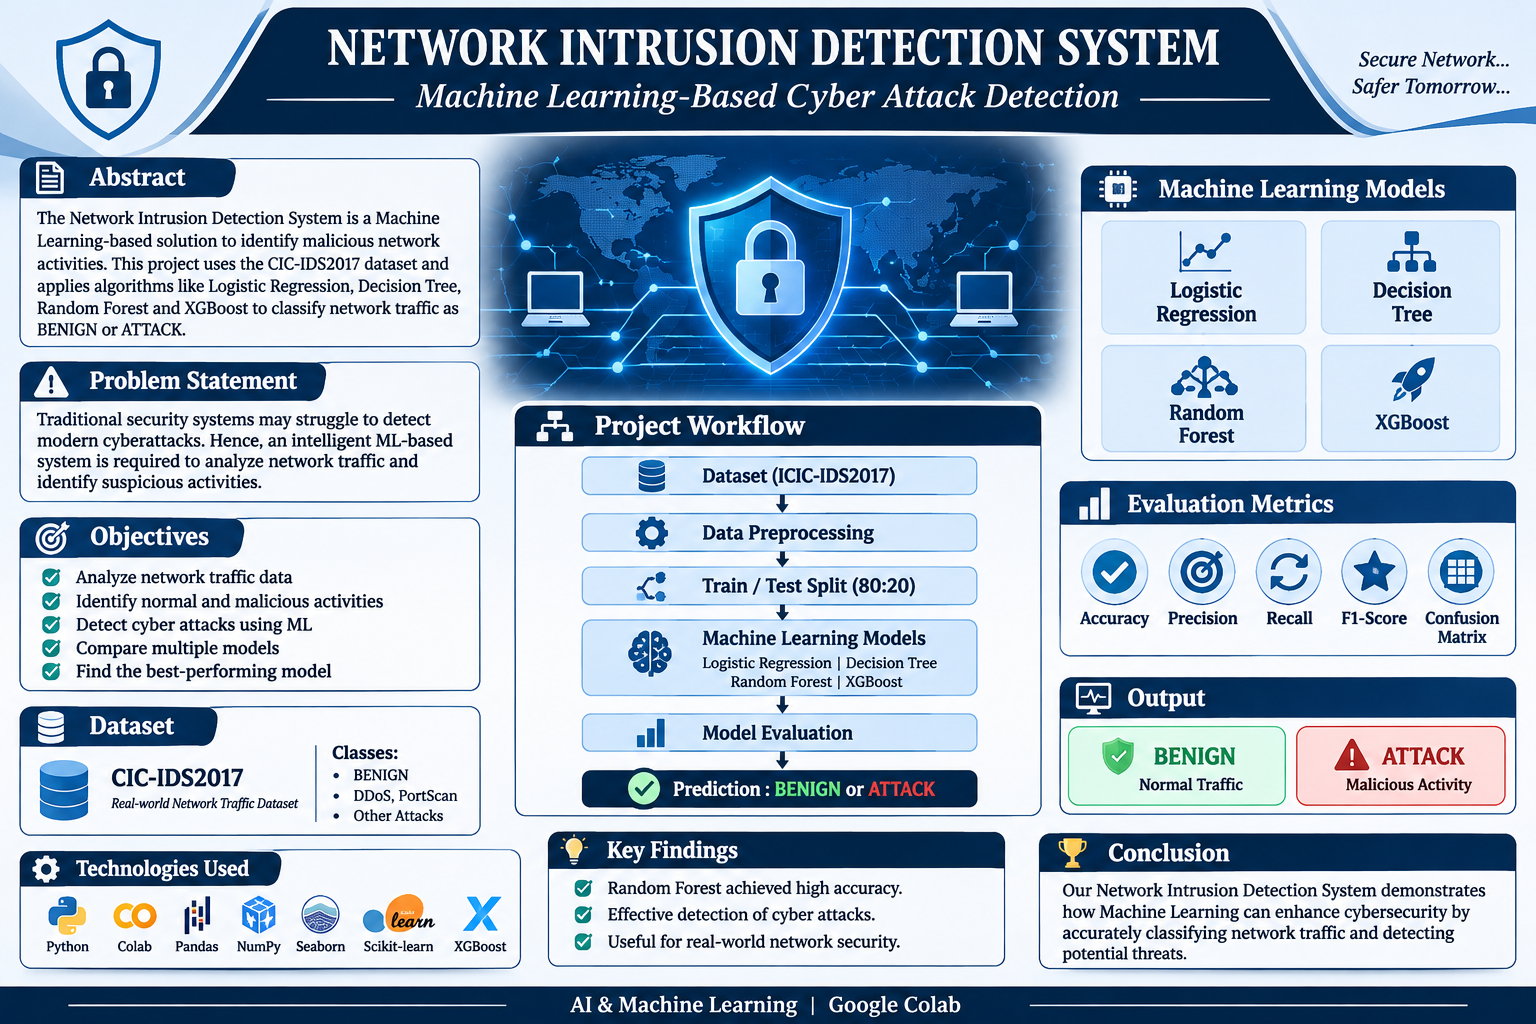

# **PROBLEM STATEMENT**

**Objective:**  
The goal of this project is to develop a machine learning-based Network Intrusion Detection System (NIDS) that analyzes network traffic records and classifies them as normal (BENIGN) or malicious (ATTACK).

**Data Description:**  
The CIC-IDS2017 dataset contains labelled network-flow records and numerical traffic features such as flow duration, packet counts, packet lengths, byte rates, and protocol-related measurements. The selected CSV files include normal traffic and attack traffic such as DDoS and PortScan.

**Approach:**  
Data preprocessing and exploratory data analysis are performed before training Logistic Regression, Decision Tree, Random Forest, and XGBoost classifiers. The models are compared using Accuracy, Precision, Recall, and F1-score.

**Expected Outcome:**  
The system should identify suspicious network-flow records and distinguish them from benign traffic. The best-performing model is selected based on evaluation results rather than assuming a model will achieve a particular accuracy.

**Practical Impact:**  
The system demonstrates how machine learning can support network monitoring and help security teams prioritize suspicious traffic. This notebook is an offline dataset-based prototype, not a live network firewall or a guarantee of detecting every attack.

# **IMPORT LIBRARIES**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Libraries imported successfully!")

Libraries imported successfully!


**👉 Interpretation:** Pandas and NumPy handle data, Matplotlib and Seaborn visualize patterns, and Scikit-learn builds and evaluates machine learning classifiers. XGBoost is installed separately in the model section.

# **LOAD DATASET**

The notebook downloads three CIC-IDS2017 CSV files from the Hugging Face dataset mirror. Run this cell in Google Colab with an active internet connection. The files are large, so allow the downloads to finish.

In [2]:
!pip -q install huggingface_hub

In [3]:
from huggingface_hub import hf_hub_download

REPO_ID = "c01dsnap/CIC-IDS2017"
REPO_TYPE = "dataset"

dataset_files = [
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"
]

dataframes = []

for filename in dataset_files:
    print("Downloading:", filename)
    file_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=filename,
        repo_type=REPO_TYPE
    )
    temp_df = pd.read_csv(file_path, low_memory=False)
    temp_df.columns = temp_df.columns.str.strip()
    dataframes.append(temp_df)

data = pd.concat(dataframes, ignore_index=True)
data.columns = data.columns.str.strip()

print("All selected files loaded successfully!")
print("Combined dataset shape:", data.shape)
display(data.head())

Downloading: Tuesday-WorkingHours.pcap_ISCX.csv


Tuesday-WorkingHours.pcap_ISCX.csv: reconstructing file:   0%|          |  0.00B /  135MB            

Tuesday-WorkingHours.pcap_ISCX.csv: downloading bytes:           |  0.00B            

Downloading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


Friday-WorkingHours-Afternoon-DDos.pcap_(…): reconstructing file:   0%|          |  0.00B / 77.1MB            

Friday-WorkingHours-Afternoon-DDos.pcap_(…): downloading bytes:           |  0.00B            

Downloading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv


Friday-WorkingHours-Afternoon-PortScan.p(…): reconstructing file:   0%|          |  0.00B / 76.9MB            

Friday-WorkingHours-Afternoon-PortScan.p(…): downloading bytes:           |  0.00B            

All selected files loaded successfully!
Combined dataset shape: (958121, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,88,640,7,4,440,358,220,0,62.857143,107.349008,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,88,900,9,4,600,2944,300,0,66.666667,132.287566,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1205,7,4,2776,2830,1388,0,396.571429,677.274651,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,88,511,7,4,452,370,226,0,64.571429,110.276708,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,773,9,4,612,2944,306,0,68.000000,134.933317,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


**👉 Interpretation:** The three selected files are combined into one DataFrame. The `Label` column identifies the original traffic category, which will be converted into the binary target in the preprocessing section.

# **DATA OVERVIEW**

In [4]:
print("Dataset shape:", data.shape)
print("\nColumn names:")
print(data.columns.tolist())

print("\nDataset information:")
data.info()

print("\nStatistical summary:")
display(data.describe(include="all").T)

print("\nOriginal attack categories:")
print(data["Label"].astype(str).str.strip().value_counts())

Dataset shape: (958121, 79)

Column names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Fla

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Destination Port,958121.0,NaN,NaN,NaN,8629.462178,18444.149246,0.0,53.0,80.0,2288.0,65532.0
Flow Duration,958121.0,NaN,NaN,NaN,10451832.742403,28285264.743608,-13.0,80.0,30987.0,1607289.0,119999977.0
Total Fwd Packets,958121.0,NaN,NaN,NaN,7.678995,591.674444,1.0,1.0,2.0,4.0,206446.0
Total Backward Packets,958121.0,NaN,NaN,NaN,8.602399,799.885093,0.0,1.0,2.0,4.0,276072.0
Total Length of Fwd Packets,958121.0,NaN,NaN,NaN,537.894901,4311.905133,0.0,2.0,44.0,90.0,2428415.0
...,...,...,...,...,...,...,...,...,...,...,...
Idle Mean,958121.0,NaN,NaN,NaN,4444532.582907,14831335.165146,0.0,0.0,0.0,0.0,120000000.0
Idle Std,958121.0,NaN,NaN,NaN,938992.267682,6543576.656321,0.0,0.0,0.0,0.0,75900000.0
Idle Max,958121.0,NaN,NaN,NaN,5112361.769931,17068733.040764,0.0,0.0,0.0,0.0,120000000.0
Idle Min,958121.0,NaN,NaN,NaN,3750458.498958,13843887.996515,0.0,0.0,0.0,0.0,120000000.0



Original attack categories:
Label
BENIGN         657329
PortScan       158930
DDoS           128027
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64


**👉 Interpretation:** This section displays the number of records, available network-flow features, data types, summary statistics, and the distribution of original traffic labels.

# **EXPLORATORY DATA ANALYSIS**

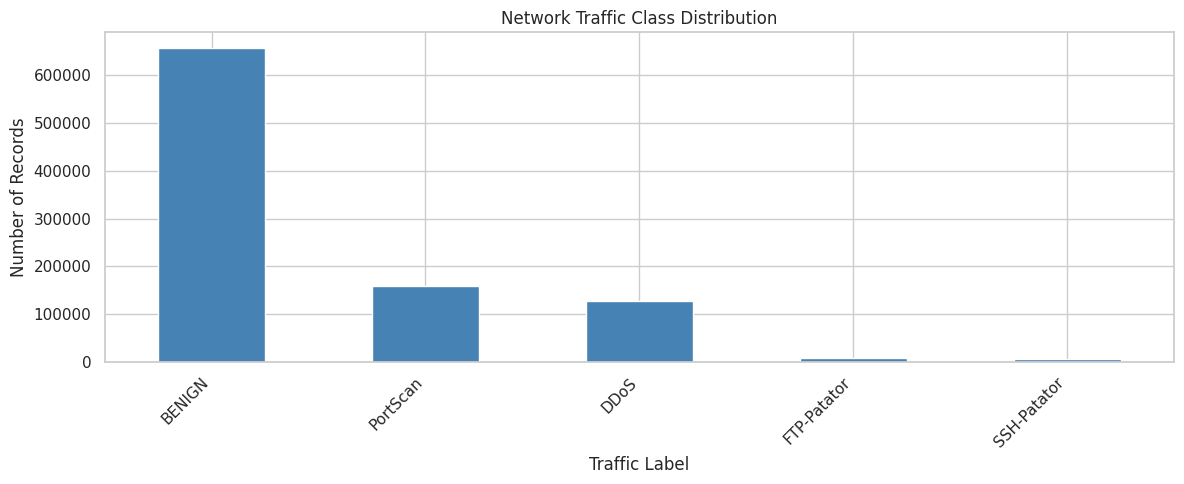

In [5]:
# Clean label text for plotting
data["Label"] = data["Label"].astype(str).str.strip()

plt.figure(figsize=(12, 5))
data["Label"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Network Traffic Class Distribution")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

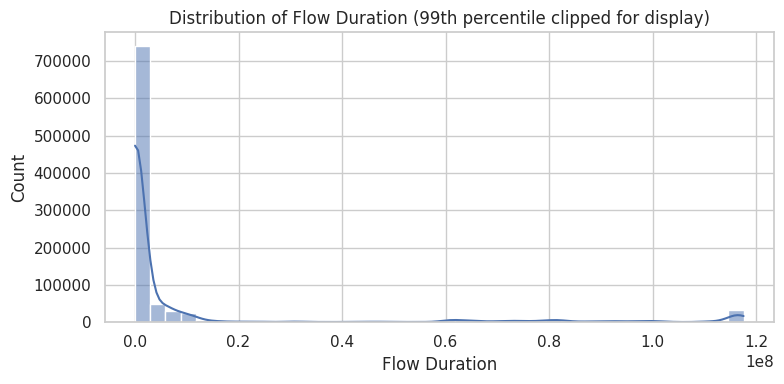

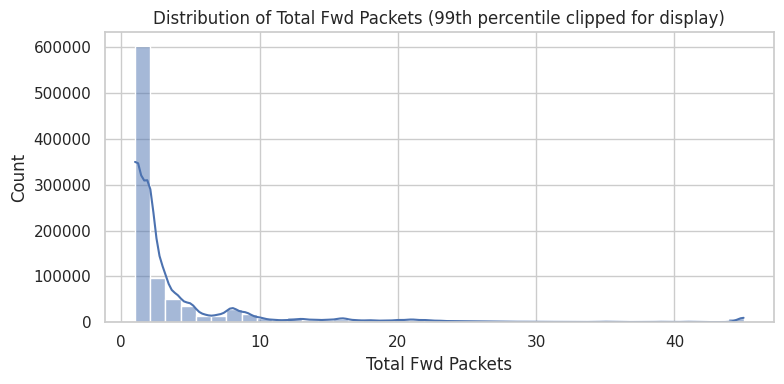

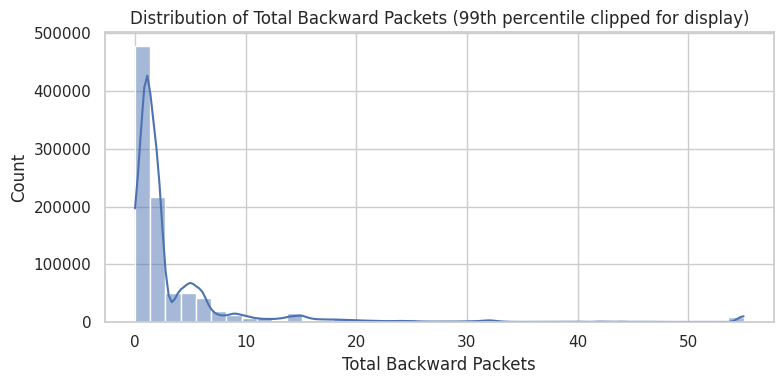

In [6]:
# Inspect distributions of selected numeric features when available
candidate_features = [
    "Flow Duration", "Total Fwd Packets",
    "Total Backward Packets", "Flow Bytes/s", "Flow Packets/s"
]
available_features = [c for c in candidate_features if c in data.columns]

for feature in available_features[:3]:
    values = pd.to_numeric(data[feature], errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(values):
        plt.figure(figsize=(8, 4))
        sns.histplot(values.clip(upper=values.quantile(0.99)), bins=40, kde=True)
        plt.title(f"Distribution of {feature} (99th percentile clipped for display)")
        plt.xlabel(feature)
        plt.tight_layout()
        plt.show()

**👉 Interpretation:** The class-distribution chart shows how many records belong to each traffic category. The feature plots help inspect the range and skewness of selected network-flow measurements. EDA plots are descriptive and do not by themselves prove that a feature causes an attack.

# **PREPROCESSING**

The target is converted into two classes: `0 = BENIGN` and `1 = ATTACK`. All other labelled categories are treated as attack traffic. Identifier-like columns are excluded from model inputs to reduce the risk of learning dataset-specific identifiers instead of traffic behaviour.

In [7]:
# Remove duplicate rows and normalize labels
data = data.drop_duplicates().copy()
data["Label"] = data["Label"].astype(str).str.strip()
data = data[data["Label"].notna() & (data["Label"] != "")].copy()

# Binary target: BENIGN = 0, every other available label = 1
data["Target"] = (data["Label"].str.upper() != "BENIGN").astype(int)

print("Binary target distribution:")
print(data["Target"].value_counts().rename(index={0: "BENIGN", 1: "ATTACK"}))

Binary target distribution:
Target
BENIGN    624806
ATTACK    227987
Name: count, dtype: int64


In [8]:
# Exclude target, original label, and identifier / timestamp columns
columns_to_drop = [
    "Label", "Target", "Flow ID", "Source IP", "Destination IP",
    "Timestamp", "Src IP", "Dst IP"
]

X = data.drop(columns=columns_to_drop, errors="ignore").copy()
y = data["Target"].copy()

# Keep numeric traffic features only
X = X.select_dtypes(include=[np.number])

# Convert infinite values to missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns that contain no usable values
X = X.dropna(axis=1, how="all")

# Remove constant columns
X = X.loc[:, X.nunique(dropna=True) > 1]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of numeric features:", X.shape[1])

Feature matrix shape: (852793, 68)
Target shape: (852793,)
Number of numeric features: 68


**👉 Interpretation:** The original labels are converted into a binary target. Non-numeric identifiers and timestamps are excluded, infinite values are changed to missing values, and columns with no usable values or no variation are removed.

# **TRAIN-TEST SPLIT AND FEATURE PREPARATION**

In [9]:
# Use a stratified sample for manageable Colab memory and runtime.
# Sampling is performed before splitting and preserves the class proportions.
MAX_RECORDS = 300000

if len(X) > MAX_RECORDS:
    X, _, y, _ = train_test_split(
        X, y,
        train_size=MAX_RECORDS,
        random_state=RANDOM_STATE,
        stratify=y
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

Training records: (240000, 68)
Testing records: (60000, 68)

Training class distribution:
Target
0    0.732658
1    0.267342
Name: proportion, dtype: float64


In [10]:
# Fit imputer and scaler on training data only to avoid data leakage.
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed!")

Preprocessing completed!


**👉 Interpretation:** The data is split into 80% training and 20% testing records using stratification. Missing-value imputation and feature scaling are fitted only on the training set, then applied to the test set to avoid data leakage. A stratified sample is used when the combined dataset is larger than 300,000 rows to keep Colab resource usage manageable.

# **MODEL 1: LOGISTIC REGRESSION**

In [11]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(
    y_test, y_pred_lr,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Logistic Regression Accuracy: 0.9783666666666667
              precision    recall  f1-score   support

      BENIGN       0.99      0.98      0.99     43960
      ATTACK       0.94      0.98      0.96     16040

    accuracy                           0.98     60000
   macro avg       0.97      0.98      0.97     60000
weighted avg       0.98      0.98      0.98     60000



**👉 Interpretation:** Logistic Regression is used as a baseline classifier. Class weighting helps account for unequal numbers of benign and attack records. Its results provide a reference point for comparing more complex models.

# **MODEL 2: DECISION TREE**

In [12]:
dt_model = DecisionTreeClassifier(
    max_depth=20,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

dt_model.fit(X_train_imputed, y_train)
y_pred_dt = dt_model.predict(X_test_imputed)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(
    y_test, y_pred_dt,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Decision Tree Accuracy: 0.9997833333333334
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     43960
      ATTACK       1.00      1.00      1.00     16040

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



**👉 Interpretation:** Decision Tree learns rule-based splits from network-flow features. It is easy to interpret, but an unrestricted tree can overfit; therefore, maximum depth is limited.

# **MODEL 3: RANDOM FOREST**

In [13]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

rf_model.fit(X_train_imputed, y_train)
y_pred_rf = rf_model.predict(X_test_imputed)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(
    y_test, y_pred_rf,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Random Forest Accuracy: 0.9998333333333334
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     43960
      ATTACK       1.00      1.00      1.00     16040

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



**👉 Interpretation:** Random Forest combines predictions from multiple decision trees. This ensemble approach can improve stability and capture non-linear relationships in network traffic features.

# **MODEL 4: XGBOOST**

In [ ]:
!pip -q install xgboost

In [14]:
from xgboost import XGBClassifier

# Weight the positive class when the training labels are imbalanced.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / max(positive_count, 1)

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

xgb_model.fit(X_train_imputed, y_train)
y_pred_xgb = xgb_model.predict(X_test_imputed)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(
    y_test, y_pred_xgb,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

XGBoost Accuracy: 0.9999166666666667
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     43960
      ATTACK       1.00      1.00      1.00     16040

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



**👉 Interpretation:** XGBoost builds boosted decision trees sequentially, with later trees learning from earlier errors. The positive-class weight is calculated from the training labels to help address class imbalance. Actual performance must be judged from the test metrics.

# **MODEL COMPARISON**

In [15]:
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

comparison_rows = []

for model_name, predictions in model_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

results = pd.DataFrame(comparison_rows).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results)

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.999917,0.999938,0.999751,0.999844
1,Random Forest,0.999833,1.000000,0.999377,0.999688
2,Decision Tree,0.999783,0.999751,0.999439,0.999595
3,Logistic Regression,0.978367,0.937968,0.984165,0.960511


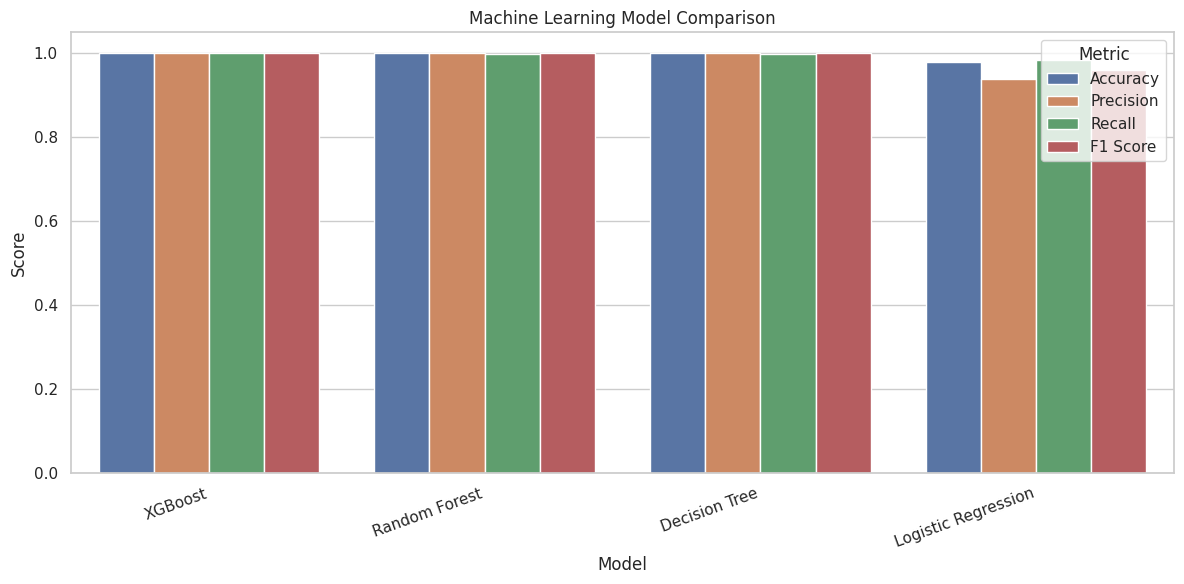

In [16]:
results_long = results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=results_long, x="Model", y="Score", hue="Metric")
plt.title("Machine Learning Model Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**👉 Interpretation:** The comparison table and chart evaluate all four classifiers using Accuracy, Precision, Recall, and F1-score. F1-score balances Precision and Recall, while Recall is especially important for understanding how many attack records are detected. The best model is selected from the measured results rather than assuming a winner in advance.

# **BEST MODEL IDENTIFICATION**

In [17]:
best_model_name = results.loc[0, "Model"]
best_predictions = model_predictions[best_model_name]

model_objects = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}
best_model = model_objects[best_model_name]

print("Best Performing Model (by F1 Score):", best_model_name)
print(results.iloc[0])

Best Performing Model (by F1 Score): XGBoost
Model         XGBoost
Accuracy     0.999917
Precision    0.999938
Recall       0.999751
F1 Score     0.999844
Name: 0, dtype: object


**👉 Interpretation:** The model with the highest test F1-score is selected as the best model for this experiment. If two models have similar F1-scores, Recall and false-negative counts should also be considered before choosing a model for a security use case.

# **CONFUSION MATRIX**

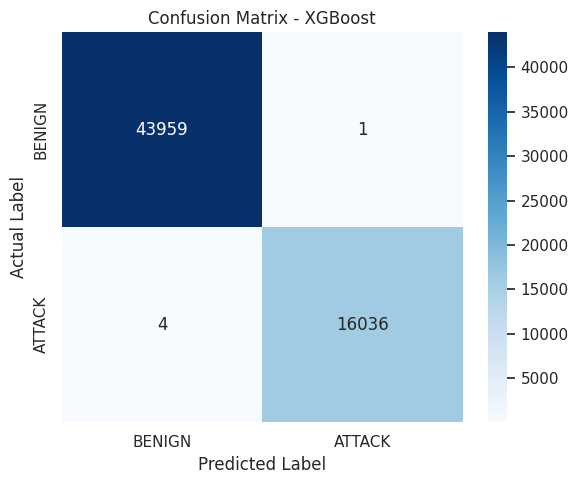

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     43960
      ATTACK       1.00      1.00      1.00     16040

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



In [18]:
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["BENIGN", "ATTACK"],
    yticklabels=["BENIGN", "ATTACK"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, best_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

**👉 Interpretation:** The confusion matrix shows correct and incorrect classifications. False negatives are attack records incorrectly predicted as benign, so they deserve particular attention in intrusion detection.

# **FEATURE IMPORTANCE**

,Feature,Importance
49,Avg Fwd Segment Size,0.116081
6,Fwd Packet Length Max,0.095655
8,Fwd Packet Length Mean,0.086380
56,Init_Win_bytes_forward,0.071382
53,Subflow Fwd Bytes,0.054939
48,Average Packet Size,0.049220
37,Packet Length Mean,0.048332
4,Total Length of Fwd Packets,0.042577
0,Destination Port,0.036781
57,Init_Win_bytes_backward,0.030452


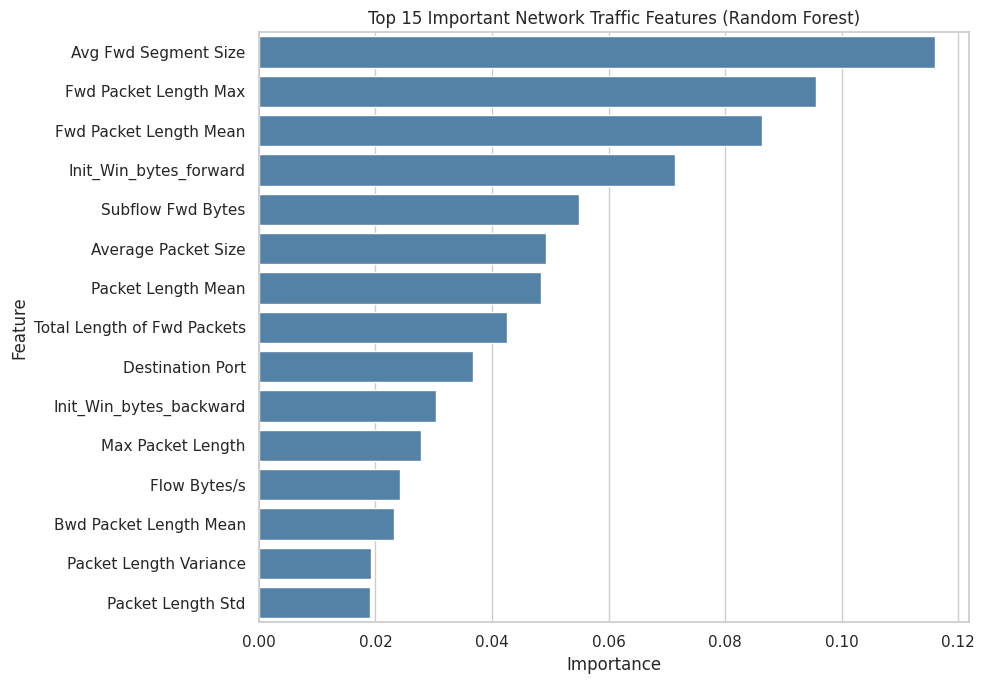

In [19]:
# Random Forest feature importance is used for an interpretable feature ranking.
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

display(feature_importance)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Top 15 Important Network Traffic Features (Random Forest)")
plt.tight_layout()
plt.show()

**👉 Interpretation:** Feature importance ranks the numeric network-flow features used by Random Forest. It describes how much the trained model relies on each feature; it does not establish a causal relationship.

# **NEW NETWORK TRAFFIC PREDICTION**

In [20]:
# Demonstration: predict one held-out test record.
# This is an offline example using a record not used for training.
new_record = X_test.iloc[[0]]
new_record_imputed = imputer.transform(new_record)

if best_model_name == "Logistic Regression":
    new_prediction = best_model.predict(
        scaler.transform(new_record_imputed)
    )[0]
else:
    new_prediction = best_model.predict(new_record_imputed)[0]

if new_prediction == 0:
    print("Predicted Network Status: BENIGN")
    print("The selected model classified this record as normal traffic.")
else:
    print("Predicted Network Status: ATTACK")
    print("The selected model classified this record as attack traffic.")

Predicted Network Status: BENIGN
The selected model classified this record as normal traffic.


**👉 Interpretation:** The selected model predicts whether a held-out network-flow record is benign or an attack. This is a demonstration using an existing dataset row; it is not a live packet-capture system.

# **SAVE TRAINED MODEL**

In [21]:
import joblib

joblib.dump(best_model, "nids_best_model.pkl")
joblib.dump(imputer, "nids_imputer.pkl")
joblib.dump(scaler, "nids_scaler.pkl")
joblib.dump(X_train.columns.tolist(), "nids_feature_columns.pkl")
joblib.dump(best_model_name, "nids_best_model_name.pkl")

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


**👉 Interpretation:** The trained classifier and preprocessing objects are saved so the same feature preparation can be reused when making future predictions.

# **CONCLUSION**

The Network Intrusion Detection System using Machine Learning was developed using selected CIC-IDS2017 network traffic records. The dataset was explored, cleaned, converted into a binary classification problem, and divided into training and testing sets.

Four machine learning algorithms—Logistic Regression, Decision Tree, Random Forest, and XGBoost—were trained and evaluated. Accuracy, Precision, Recall, F1-score, and the Confusion Matrix were used to compare their performance. The best-performing model was selected based on the measured test F1-score.

The project demonstrates how machine learning can classify network-flow records as BENIGN or ATTACK and support the analysis of suspicious network activity. The system is an offline prototype and requires additional testing on separate capture sessions and live traffic before any operational security use.

# **SUCCESSFULLY COMPLETED**

**Project:** Network Intrusion Detection System Using Machine Learning  
**Dataset:** CIC-IDS2017 (selected CSV files)  
**Models:** Logistic Regression, Decision Tree, Random Forest, XGBoost  
**Output:** BENIGN / ATTACK classification

*Note: Record the actual metric values produced by your Colab run in the final project report. Do not copy or assume accuracy values before running the notebook.*